Вариант 3

**Задание 1**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

N = 10000
SEED = 2026
alpha = 0.05

X_values = np.array([-5, -2, -1, 0.5, 1, 10])
X_probs = np.array([0.15, 0.20, 0.20, 0.10, 0.30, 0.05])

n, p = 14, 0.38
Y_values = np.arange(n + 1)
Y_probs = stats.binom.pmf(Y_values, n, p)

In [ ]:
def simulate_manual_X(N, random_state=None):
    rng = np.random.default_rng(random_state)
    result = []

    for _ in range(N):
        u = rng.random()
        s = 0

        for x, q in zip(X_values, X_probs):
            s += q
            if u < s:
                result.append(x)
                break

    return np.array(result)

In [ ]:
def simulate_manual_Y(N, random_state=None):
    rng = np.random.default_rng(random_state)
    result = []

    for _ in range(N):
        successes = 0

        for _ in range(n):
            if rng.random() < p:
                successes += 1

        result.append(successes)

    return np.array(result)

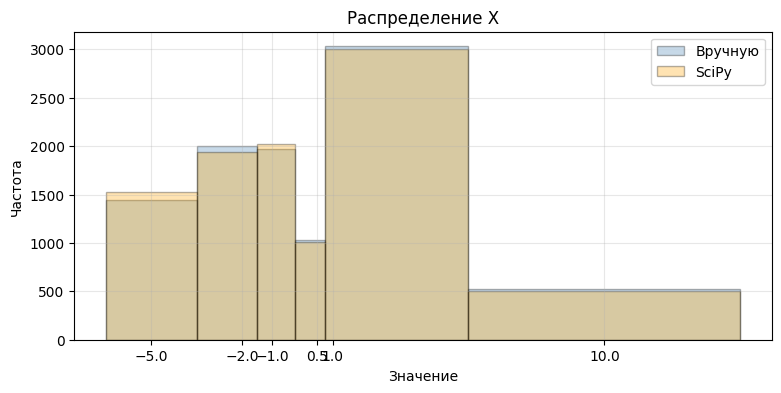

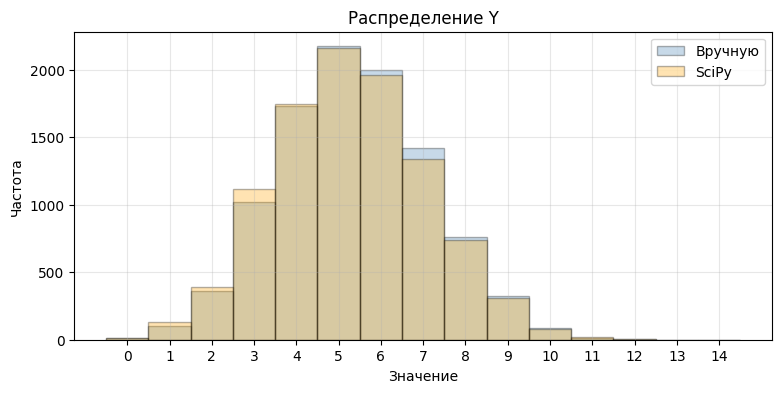

In [ ]:
rng = np.random.default_rng(SEED)

X_manual = simulate_manual_X(N, rng)
Y_manual = simulate_manual_Y(N, rng)

X_lib = stats.rv_discrete(
    values=(X_values, X_probs)
).rvs(size=N, random_state=rng)

Y_lib = stats.binom.rvs(n, p, size=N, random_state=rng)

samples = {
    'X вручную': X_manual,
    'X SciPy': X_lib,
    'Y вручную': Y_manual,
    'Y SciPy': Y_lib
}

x_bins = [-6.5, -3.5, -1.5, -0.25, 0.75, 5.5, 14.5]
y_bins = np.arange(-0.5, n + 1.5)

for title, a, b, bins, ticks in [
    ('X', X_manual, X_lib, x_bins, X_values),
    ('Y', Y_manual, Y_lib, y_bins, Y_values)
]:
    plt.figure(figsize=(9, 4))

    plt.hist(a, bins=bins, alpha=0.3,
             label='Вручную', color='steelblue', edgecolor='black')

    plt.hist(b, bins=bins, alpha=0.3,
             label='SciPy', color='orange', edgecolor='black')

    plt.title(f'Распределение {title}')
    plt.xlabel('Значение')
    plt.ylabel('Частота')
    plt.xticks(ticks)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

Оба способа дали близкие распределения частот. Для X наиболее часто встречается значение 1, для Y — значение 5, что согласуется с теоретическими вероятностями. Есть небольшие различия между выборками из-за случайности моделирования.

**Задание 2**

In [ ]:
def manual_moments(a):
    mean = sum(a) / len(a)
    second = sum(x*x for x in a) / len(a)
    var = sum((x - mean)**2 for x in a) / (len(a) - 1)

    return mean, second, var


X вручную  (вручную / NumPy / теория)
Среднее: -0.43970 / -0.43970 / -0.50000
Второй момент: 10.18300 / 10.18300 / 10.07500
Дисперсия: 9.99066 / 9.99066 / 9.82500

X SciPy  (вручную / NumPy / теория)
Среднее: -0.50295 / -0.50295 / -0.50000
Второй момент: 10.11047 / 10.11047 / 10.07500
Дисперсия: 9.85850 / 9.85850 / 9.82500

Y вручную  (вручную / NumPy / теория)
Среднее: 5.35950 / 5.35950 / 5.32000
Второй момент: 31.93190 / 31.93190 / 31.60080
Дисперсия: 3.20798 / 3.20798 / 3.29840

Y SciPy  (вручную / NumPy / теория)
Среднее: 5.28960 / 5.28960 / 5.32000
Второй момент: 31.27820 / 31.27820 / 31.60080
Дисперсия: 3.29866 / 3.29866 / 3.29840


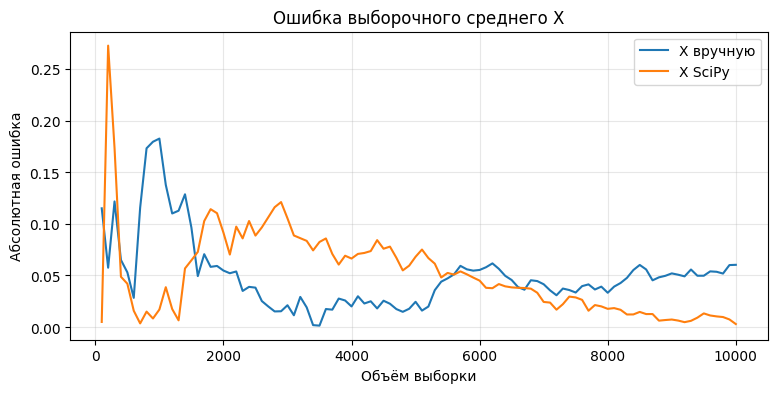

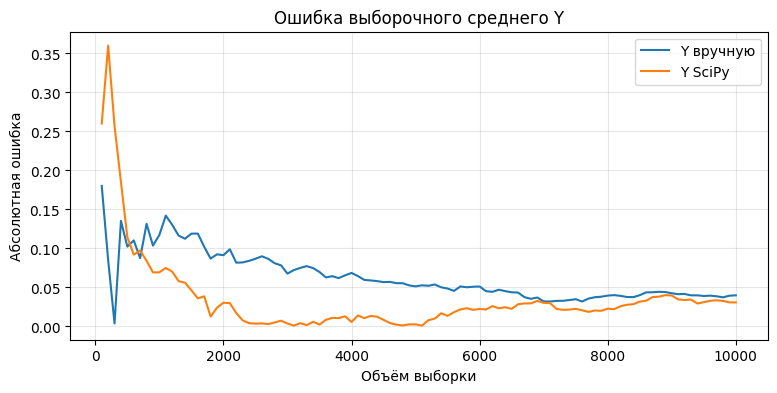

In [ ]:
mx = sum(x*q for x, q in zip(X_values, X_probs))
m2x = sum(x*x*q for x, q in zip(X_values, X_probs))

my = n*p
vy = n*p*(1-p)

theory = {
    'X': (mx, m2x, m2x - mx**2),
    'Y': (my, vy + my**2, vy)
}

for name, a in samples.items():
    manual = manual_moments(a)
    library = (np.mean(a), np.mean(a**2), np.var(a, ddof=1))

    print(f'\n{name}  (вручную / NumPy / теория)')

    for label, v1, v2, vt in zip(
        ['Среднее', 'Второй момент', 'Дисперсия'],
        manual, library, theory[name[0]]
    ):
        print(f'{label}: {v1:.5f} / {v2:.5f} / {vt:.5f}')


sizes = range(100, N + 1, 100)

for var in 'XY':
    plt.figure(figsize=(9, 4))

    for name, a in samples.items():
        if name[0] == var:
            errors = [
                abs(sum(a[:k])/k - theory[var][0])
                for k in sizes
            ]
            plt.plot(sizes, errors, label=name)

    plt.title(f'Ошибка выборочного среднего {var}')
    plt.xlabel('Объём выборки')
    plt.ylabel('Абсолютная ошибка')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

Результаты ручного и библиотечного вычисления выборочных характеристик совпали. Выборочные значения близки к теоретическим. С увеличением объёма выборки отклонение среднего от математического ожидания уменьшаются (не монотонно)

**Задание 3**


X: значение | вероятность | вручную | SciPy
   -5 | 0.15000 | 0.14420 | 0.15270
   -2 | 0.20000 | 0.20060 | 0.19370
   -1 | 0.20000 | 0.19690 | 0.20220
  0.5 | 0.10000 | 0.10280 | 0.10070
    1 | 0.30000 | 0.30300 | 0.30080
   10 | 0.05000 | 0.05250 | 0.04990


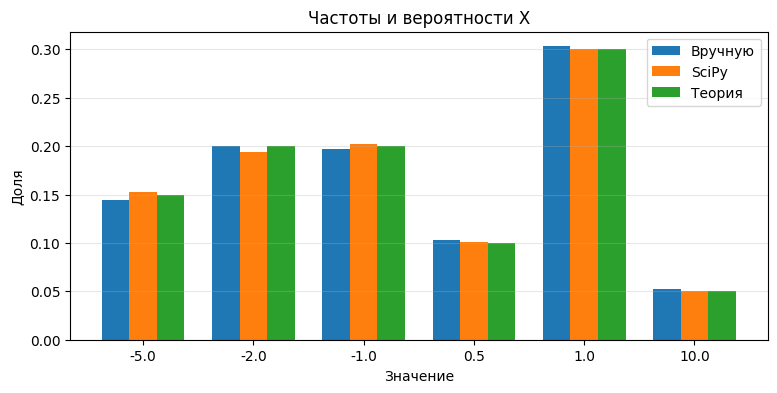


Y: значение | вероятность | вручную | SciPy
    0 | 0.00124 | 0.00110 | 0.00140
    1 | 0.01064 | 0.01050 | 0.01280
    2 | 0.04239 | 0.03580 | 0.03900
    3 | 0.10393 | 0.10220 | 0.11160
    4 | 0.17518 | 0.17340 | 0.17440
    5 | 0.21474 | 0.21720 | 0.21600
    6 | 0.19742 | 0.19950 | 0.19570
    7 | 0.13828 | 0.14230 | 0.13410
    8 | 0.07416 | 0.07570 | 0.07370
    9 | 0.03030 | 0.03230 | 0.03120
   10 | 0.00929 | 0.00840 | 0.00820
   11 | 0.00207 | 0.00140 | 0.00170
   12 | 0.00032 | 0.00020 | 0.00020
   13 | 0.00003 | 0.00000 | 0.00000
   14 | 0.00000 | 0.00000 | 0.00000


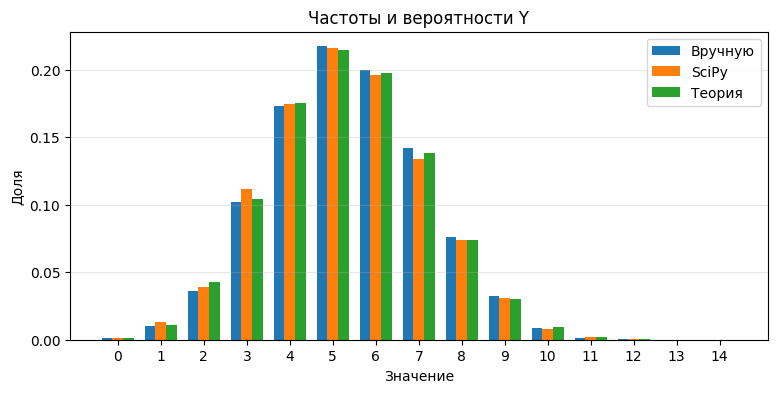

X вручную разница со SciPy: 0.0
X SciPy разница со SciPy: 0.0


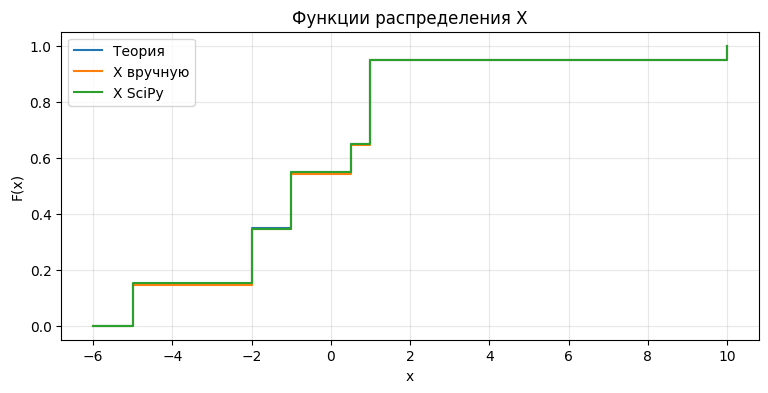

X вручную D_N = 0.0083
X SciPy D_N = 0.0036


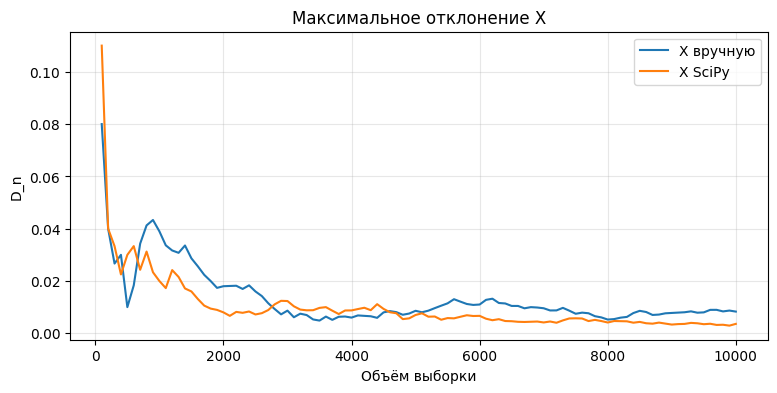

Y вручную разница со SciPy: 0.0
Y SciPy разница со SciPy: 0.0


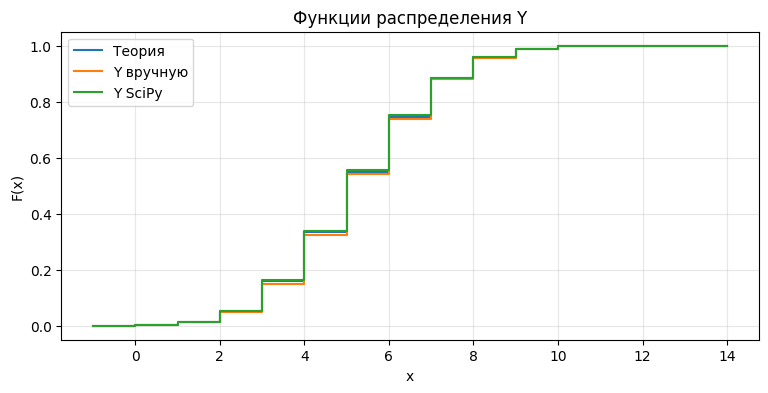

Y вручную D_N = 0.010391
Y SciPy D_N = 0.007072


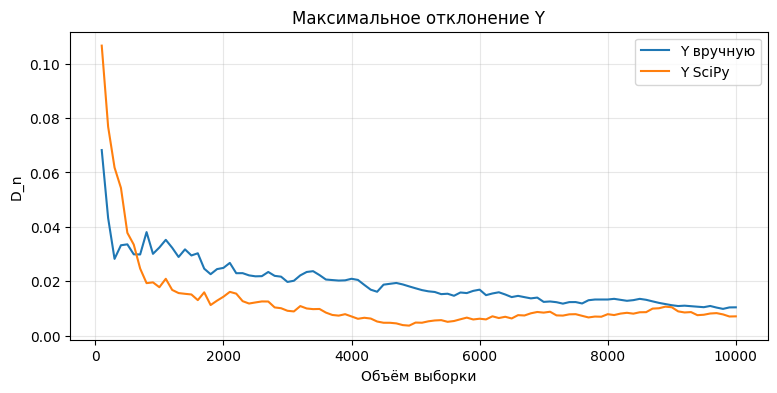

In [ ]:
for var, values, probs in [
    ('X', X_values, X_probs),
    ('Y', Y_values, Y_probs)
]:
    a = samples[f'{var} вручную']
    b = samples[f'{var} SciPy']

    fa = np.array([np.sum(a == x)/N for x in values])
    fb = np.array([np.sum(b == x)/N for x in values])

    print(f'\n{var}: значение | вероятность | вручную | SciPy')

    for x, q, f1, f2 in zip(values, probs, fa, fb):
        print(f'{x:5g} | {q:.5f} | {f1:.5f} | {f2:.5f}')

    pos = np.arange(len(values))

    plt.figure(figsize=(9, 4))
    plt.bar(pos - 0.25, fa, width=0.25, label='Вручную')
    plt.bar(pos, fb, width=0.25, label='SciPy')
    plt.bar(pos + 0.25, probs, width=0.25, label='Теория')

    plt.xticks(pos, values)
    plt.title(f'Частоты и вероятности {var}')
    plt.xlabel('Значение')
    plt.ylabel('Доля')
    plt.legend()
    plt.grid(axis='y', alpha=0.3)
    plt.show()


def F_empirical(a, x):
    return np.sum(a <= x) / len(a)


def Dn(a, values, probs):
    f = 0
    d = 0

    for x, q in zip(values, probs):
        f += q
        d = max(d, abs(F_empirical(a, x) - f))

    return d


for var, values, probs in [
    ('X', X_values, X_probs),
    ('Y', Y_values, Y_probs)
]:
    points = [values[0] - 1] + list(values)

    F = [0]
    for q in probs:
        F.append(F[-1] + q)

    plt.figure(figsize=(9, 4))
    plt.step(points, F, where='post', label='Теория')

    for name, a in samples.items():
        if name[0] == var:
            ours = [F_empirical(a, x) for x in values]
            scipy_F = stats.ecdf(a).cdf.evaluate(values)

            print(name, 'разница со SciPy:',
                  max(abs(np.array(ours) - scipy_F)))

            plt.step(
                points,
                [F_empirical(a, x) for x in points],
                where='post',
                label=name
            )

    plt.title(f'Функции распределения {var}')
    plt.xlabel('x')
    plt.ylabel('F(x)')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    plt.figure(figsize=(9, 4))

    for name, a in samples.items():
        if name[0] == var:
            deviations = [
                Dn(a[:k], values, probs)
                for k in sizes
            ]

            plt.plot(sizes, deviations, label=name)
            print(name, 'D_N =', round(deviations[-1], 6))

    plt.title(f'Максимальное отклонение {var}')
    plt.xlabel('Объём выборки')
    plt.ylabel('D_n')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

Относительные частоты близки к теоретическим вероятностям. Собственная реализация эмпирической функции распределения совпала с SciPy. При N = 10 000 максимальные отклонения составили 0,0036–0,0104. С увеличением объёма выборки отклонения уменьшаются

**Задание 4**

In [ ]:
print('H0: выборки имеют заданные распределения')

print('Минимальная ожидаемая частота для X:',
      min(N*X_probs))

print('Ожидаемые частоты для Y:',
      np.round(N*Y_probs, 2))

print('Для Y объединяем категории 11–14')

for name, a in samples.items():
    if name[0] == 'X':
        observed = [np.sum(a == x) for x in X_values]
        expected = N * X_probs
    else:
        observed = [np.sum(a == k) for k in range(11)]
        observed.append(np.sum(a >= 11))

        expected = [N*q for q in Y_probs[:11]]
        expected.append(N*sum(Y_probs[11:]))

    assert min(expected) >= 5

    result = stats.chisquare(observed, f_exp=expected)

    df = len(observed) - 1
    critical = stats.chi2.ppf(1 - alpha, df)

    if result.pvalue >= alpha:
        decision = 'H0 не отвергается'
    else:
        decision = 'H0 отвергается'

    print(f'\n{name}')
    print(f'χ² = {result.statistic:.4f}')
    print(f'Степени свободы = {df}')
    print(f'Критическое значение = {critical:.4f}')
    print(f'p-value = {result.pvalue:.4f}')
    print(decision)

H0: выборки имеют заданные распределения
Минимальная ожидаемая частота для X: 500.0
Ожидаемые частоты для Y: [1.24000e+01 1.06420e+02 4.23940e+02 1.03935e+03 1.75180e+03 2.14737e+03
 1.97420e+03 1.38285e+03 7.41610e+02 3.03020e+02 9.28600e+01 2.07000e+01
 3.17000e+00 3.00000e-01 1.00000e-02]
Для Y объединяем категории 11–14.

X вручную
χ² = 5.0752
Степени свободы = 5
Критическое значение = 11.0705
p-value = 0.4068
H0 не отвергается

X SciPy
χ² = 2.7848
Степени свободы = 5
Критическое значение = 11.0705
p-value = 0.7331
H0 не отвергается

Y вручную
χ² = 17.8223
Степени свободы = 11
Критическое значение = 19.6751
p-value = 0.0858
H0 не отвергается

Y SciPy
χ² = 17.1551
Степени свободы = 11
Критическое значение = 19.6751
p-value = 0.1034
H0 не отвергается


Для X все ожидаемые частоты удовлетворяют условию применимости критерия. Для Y потребовалось объединение категорий 11–14. Во всех четырёх случаях p-value превышает 0,05, поэтому гипотеза H₀ не отвергается. Статистически значимых отклонений от заданных распределений нет